# Multimodal forecast evaluation

In [1]:
import xarray as xr
import zarr

path = "/Net/Groups/BGI/tscratch/weathergenerator/tmp/inference_lst/train_lst.zarr"
g = zarr.open_group(path, mode="r")

In [2]:
ds = xr.Dataset(
    {
        "lst": (("forecast_time", "step", "lead_hour", "pixel"), g["lst"][:]),
        "mask": (("forecast_time", "step", "lead_hour", "pixel"), g["mask"][:]),
        "step_doy": (("forecast_time", "step"), g["step_doy"][:]),
        "spatial_index": (("forecast_time",), g["spatial_index"][:]),
    },
    coords={
        "forecast_time": g["forecast_time"][:].astype(str),
    },
)

In [3]:
ds

<xarray.Dataset> Size: 15MB
Dimensions:        (forecast_time: 10378, step: 7, lead_hour: 24, pixel: 1)
Coordinates:
  * forecast_time  (forecast_time) <U26 1MB '2024-01-16 00:00:00' ... '2024-0...
Dimensions without coordinates: step, lead_hour, pixel
Data variables:
    lst            (forecast_time, step, lead_hour, pixel) float32 7MB 288.5 ...
    mask           (forecast_time, step, lead_hour, pixel) float32 7MB 1.0 .....
    step_doy       (forecast_time, step) int32 291kB 16 17 18 19 ... 165 166 167
    spatial_index  (forecast_time) int64 83kB 254349 254349 ... 2153615 2153615

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

[  484   486  1014  1028  1456  1474  1750  2467  2649  3384  3969  4039
  4323  4501  4751  5135  5265  5357  5401  5651  5963  6181  6435  8087
  8915  9017  9329  9626 10032 10177 10376]
pixels forecast from 2024-06-08 00:00:00 : 31


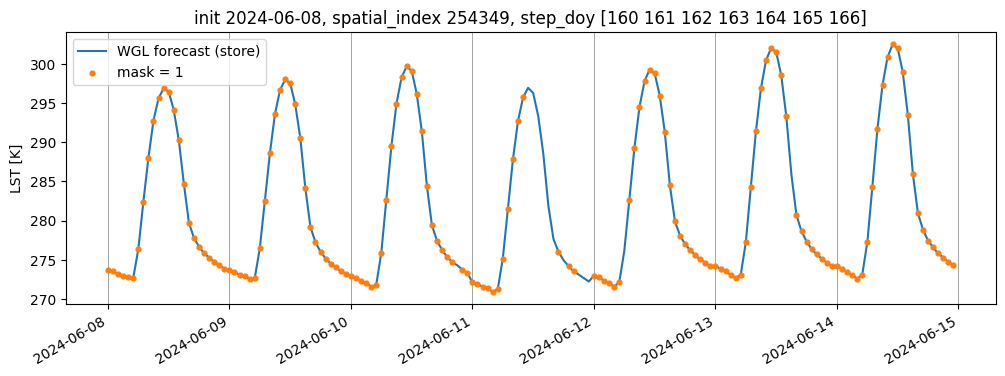

In [8]:
init_time = "2024-06-08 00:00:00"

# forecast_time repeats once per pixel, so select rows by value
is_init = ds.forecast_time.values == init_time
rows_at_init = np.flatnonzero(is_init)
print(rows_at_init)
pixels_at_init = ds.spatial_index.values[rows_at_init]
print("pixels forecast from", init_time, ":", len(pixels_at_init))

spatial_index = pixels_at_init[0]
row = rows_at_init[pixels_at_init == spatial_index][0]

fc_store = ds.isel(forecast_time=row, pixel=0)
lst_store = fc_store.lst.values.reshape(-1)  # (step, lead_hour) -> 168 h
mask_store = fc_store["mask"].values.reshape(-1)

lead_time = pd.timedelta_range("0h", periods=7 * 24, freq="h")
valid_time = pd.Timestamp(init_time) + lead_time
observed = mask_store == 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(valid_time, lst_store, color="tab:blue", label="WGL forecast (store)")
ax.scatter(
    valid_time[observed],
    lst_store[observed],
    color="tab:orange",
    s=12,
    zorder=3,
    label="mask = 1",
)
day_starts = pd.date_range(init_time, periods=8, freq="D")
for day_start in day_starts:
    ax.axvline(day_start, color="grey", linewidth=0.5)
step_doys = fc_store.step_doy.values
ax.set_title(f"init {init_time[:10]}, spatial_index {spatial_index}, step_doy {step_doys}")
ax.set_ylabel("LST [K]")
ax.legend()
fig.autofmt_xdate()
plt.show()

{'init_time': 322, 'lead_time': 168, 'pixel': 108}
max |store - baseline| lst: 0.0
mask identical: True
lat -28.855, lon 27.055, global_idx 5249345


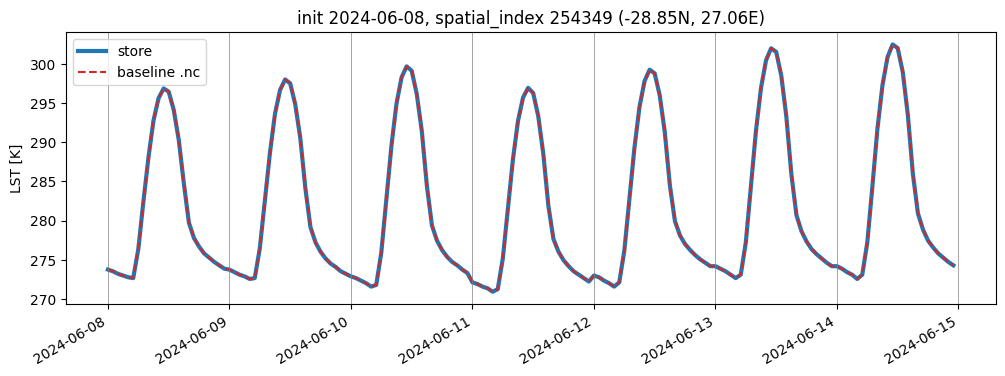

In [9]:
OUT = "/Net/Groups/BGI/people/mwessel/deep_lst/assets/baselines/WGL/v1/weathergen_landv0.nc"
baseline = xr.open_dataset(OUT)
print(dict(baseline.sizes))  # expect init_time 322, lead_time 168, pixel 108

is_pixel = baseline.spatial_index.values == spatial_index
pixel_pos = np.flatnonzero(is_pixel)[0]
fc_baseline = baseline.sel(init_time=pd.Timestamp(init_time)).isel(pixel=pixel_pos)
lst_baseline = fc_baseline.lst.values
mask_baseline = fc_baseline["mask"].values

lst_abs_diff = np.abs(lst_store - lst_baseline)
print("max |store - baseline| lst:", np.nanmax(lst_abs_diff))
print("mask identical:", np.array_equal(mask_store, mask_baseline))
lat = float(fc_baseline.lat)
lon = float(fc_baseline.lon)
print(f"lat {lat:.3f}, lon {lon:.3f}, global_idx {int(fc_baseline.global_idx)}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(valid_time, lst_store, color="tab:blue", linewidth=3, label="store")
ax.plot(valid_time, lst_baseline, color="tab:red", linestyle="--", label="baseline .nc")
for day_start in day_starts:
    ax.axvline(day_start, color="grey", linewidth=0.5)
ax.set_title(f"init {init_time[:10]}, spatial_index {spatial_index} ({lat:.2f}N, {lon:.2f}E)")
ax.set_ylabel("LST [K]")
ax.legend()
fig.autofmt_xdate()
plt.show()

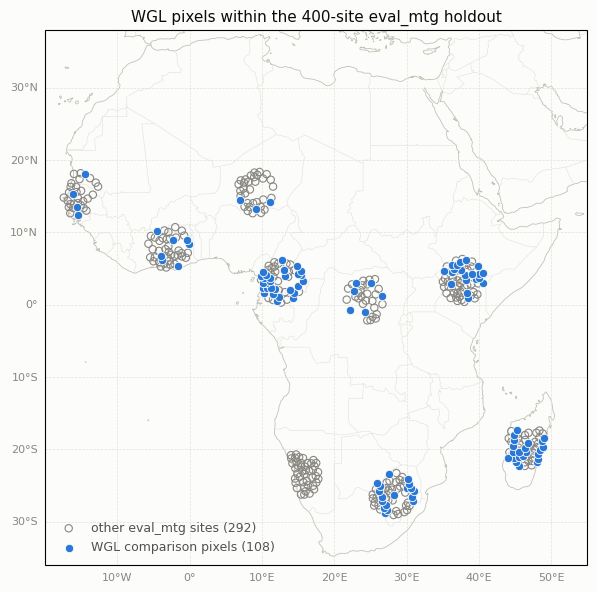

In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from eodata.grids.majortom import MajorTomGrid

wgl = xr.open_dataset("/Net/Groups/BGI/people/mwessel/deep_lst/assets/baselines/WGL/v1/weathergen_landv0.nc")
wgl_ids = wgl.global_idx.values.astype(np.int64)

holdout_ids = np.load("/Net/Groups/BGI/people/mwessel/deep_lst/assets/spatial/indices_eval_mtg.npz")[
    "src_indices"
].astype(np.int64)
other_ids = np.setdiff1d(holdout_ids, wgl_ids)
centers = np.asarray(MajorTomGrid(5).centers)  # col 0 = lon, col 1 = lat

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": ccrs.PlateCarree()})
fig.patch.set_facecolor("#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.set_extent([-20, 55, -36, 38], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#c3c2b7", linewidth=0.6)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#e1e0d9", linewidth=0.4)
grid = ax.gridlines(draw_labels=True, color="#e1e0d9", linewidth=0.5, linestyle="--")
grid.top_labels = grid.right_labels = False
grid.xlabel_style = grid.ylabel_style = {"color": "#898781", "size": 8}

ax.scatter(
    centers[other_ids, 0],
    centers[other_ids, 1],
    s=28,
    facecolors="none",
    edgecolors="#898781",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    label=f"other eval_mtg sites ({len(other_ids)})",
    zorder=3,
)
ax.scatter(
    wgl.lon.values,
    wgl.lat.values,
    s=36,
    color="#2a78d6",
    edgecolors="#fcfcfb",
    linewidths=0.6,
    transform=ccrs.PlateCarree(),
    label=f"WGL comparison pixels ({len(wgl_ids)})",
    zorder=4,
)
ax.set_title("WGL pixels within the 400-site eval_mtg holdout", color="#0b0b0b", fontsize=11)
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor="#52514e")
plt.show()